## **Problem Statement**

### Business Context
The prices of stocks listed on global exchanges are influenced by company performance, market sentiment, and news coverage. Investment firms need sophisticated tools to analyze market sentiment and integrate this into their investment strategies.

### Problem Definition
An investment startup aims to leverage AI to interpret stock-related news and its impact on stock prices. They have collected historical daily news for a NASDAQ-listed company (Apple Inc. â€“ AAPL) along with its daily stock price and trade volume data.

**Tasks:**
1. Perform Exploratory Data Analysis (EDA) on the dataset
2. Build a sentiment analysis system using Word2Vec, GloVe, and Sentence Transformer embeddings
3. Summarize weekly news using a Large Language Model (LLM) to identify key positive/negative events

### Data Dictionary
| Column | Description |
|--------|-------------|
| `Date` | The date the news was released |
| `News` | Content of news articles that could affect the company's stock price |
| `Open` | Stock price (in $) at the beginning of the day |
| `High` | Highest stock price (in $) reached during the day |
| `Low` | Lowest stock price (in $) reached during the day |
| `Close` | Adjusted stock price (in $) at the end of the day |
| `Volume` | Number of shares traded during the day |
| `Label` | Sentiment polarity: **1** = Positive, **0** = Neutral, **-1** = Negative |

## **Installing and Importing Necessary Libraries**

In [4]:
# Install required libraries
!pip install -U sentence-transformers gensim transformers tqdm scikit-learn -q
!pip install wordcloud nltk -q

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re, string, json, warnings

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, accuracy_score)
from gensim.models import Word2Vec, KeyedVectors
from sentence_transformers import SentenceTransformer

import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

warnings.filterwarnings("ignore")
%matplotlib inline
plt.style.use("seaborn-v0_8-whitegrid")
SEED = 42
print("All libraries imported successfully!")

All libraries imported successfully!


## **Loading the Dataset**

> **Colab**: Mount Google Drive first (cell below), then run all cells. Files expected at:
> $DRIVE_BASE/stock_news.csv` and `/content/drive/MyDrive/Python_course/ADDNLPGENAI/glove.6B.100d.txt.word2vec`

In [6]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# File paths
DATA_PATH  = '/content/drive/MyDrive/Python_course/ADDNLPGENAI/stock_news.csv'
GLOVE_PATH = '/content/drive/MyDrive/Python_course/ADDNLPGENAI/glove.6B.100d.txt.word2vec'

# Load dataset
df = pd.read_csv(DATA_PATH)
df["Date"] = pd.to_datetime(df["Date"])
print(f"Dataset loaded. Shape: {df.shape}")
df.head()

Mounted at /content/drive
Dataset loaded. Shape: (349, 8)


,Date,News,Open,High,Low,Close,Volume,Label
0,2019-01-02,The tech sector experienced a significant dec...,41.740002,42.244999,41.482498,40.246914,130672400,-1
1,2019-01-02,Apple lowered its fiscal Q1 revenue guidance ...,41.740002,42.244999,41.482498,40.246914,130672400,-1
2,2019-01-02,Apple cut its fiscal first quarter revenue fo...,41.740002,42.244999,41.482498,40.246914,130672400,-1
3,2019-01-02,This news article reports that yields on long...,41.740002,42.244999,41.482498,40.246914,130672400,-1
4,2019-01-02,Apple's revenue warning led to a decline in U...,41.740002,42.244999,41.482498,40.246914,130672400,-1


## **Data Overview**

In [7]:
print("=== Shape ===")
print(df.shape)
print("\n=== Data Types ===")
print(df.dtypes)
print("\n=== Missing Values ===")
print(df.isnull().sum())
print(f"\n=== Duplicate Rows: {df.duplicated().sum()} ===")
print(f"\n=== Date Range: {df['Date'].min().date()} to {df['Date'].max().date()} ===")
print(f"\n=== Unique Dates: {df['Date'].nunique()} ===")

=== Shape ===
(349, 8)

=== Data Types ===
Date      datetime64[ns]
News              object
Open             float64
High             float64
Low              float64
Close            float64
Volume             int64
Label              int64
dtype: object

=== Missing Values ===
Date      0
News      0
Open      0
High      0
Low       0
Close     0
Volume    0
Label     0
dtype: int64

=== Duplicate Rows: 0 ===

=== Date Range: 2019-01-02 to 2019-04-30 ===

=== Unique Dates: 71 ===


In [8]:
# Statistical summary of numerical columns
df.describe().round(2)

,Date,Open,High,Low,Close,Volume,Label
count,349,349.00,349.00,349.00,349.00,3.490000e+02,349.00
mean,2019-02-16 16:05:30.085959936,46.23,46.70,45.75,44.93,1.289482e+08,-0.05
min,2019-01-02 00:00:00,37.57,37.82,37.30,36.25,4.544800e+07,-1.00
25%,2019-01-14 00:00:00,41.74,42.24,41.48,40.25,1.032720e+08,-1.00
50%,2019-02-05 00:00:00,45.97,46.03,45.64,44.60,1.156272e+08,0.00
75%,2019-03-22 00:00:00,50.71,50.85,49.78,49.11,1.511252e+08,0.00
max,2019-04-30 00:00:00,66.82,67.06,65.86,64.81,2.444392e+08,1.00
std,NaN,6.44,6.51,6.39,6.40,4.317031e+07,0.72


In [9]:
# Sample news articles by sentiment
label_map = {-1: "Negative", 0: "Neutral", 1: "Positive"}
for label, name in label_map.items():
    sample = df[df["Label"] == label].iloc[0]
    print(f"\n[{name}] Date: {sample['Date'].date()}")
    print(f"  News: {str(sample['News'])[:250]}...")
    print(f"  Close: ${sample['Close']:.2f}")


[Negative] Date: 2019-01-02
  News:  The tech sector experienced a significant decline in the aftermarket following Apple's Q1 revenue warning. Notable suppliers, including Skyworks, Broadcom, Lumentum, Qorvo, and TSMC, saw their stocks drop in response to Apple's downward revision of ...
  Close: $40.25

[Neutral] Date: 2019-01-02
  News: Apple CEO Tim Cook discussed the company's Q1 warning on CNBC, attributing US-China trade tensions as a factor. Despite not mentioning iPhone unit sales specifically, Cook indicated Apple may comment on them again. Services revenue is projected to ex...
  Close: $40.25

[Positive] Date: 2019-01-02
  News:  Roku Inc has announced plans to offer premium video channels on a subscription basis through its free streaming service, The Roku Channel. Partners include CBS Corp's Showtime, Lionsgate's Starz, and Viacom Inc's Noggin. This model follows Amazon's ...
  Close: $40.25


## **Exploratory Data Analysis**

### Univariate Analysis
Analysis of individual variables â€” distributions, frequencies, and summary statistics.

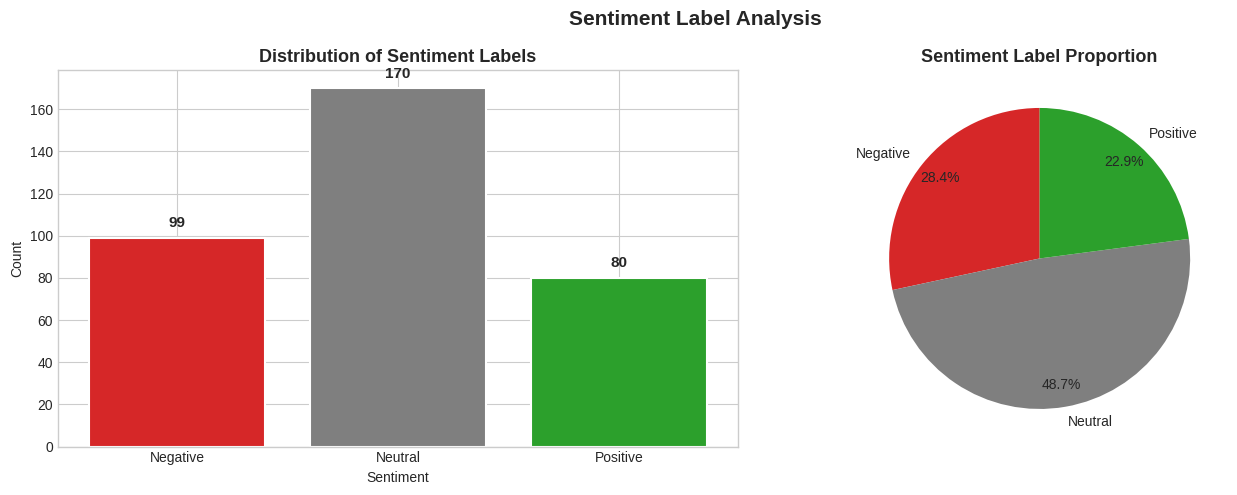


Sentiment Distribution:
  Negative  :    99  (28.4%)
  Neutral   :   170  (48.7%)
  Positive  :    80  (22.9%)


In [10]:
# 1. Sentiment Label Distribution
label_map = {-1: "Negative", 0: "Neutral", 1: "Positive"}
colors = {"Negative": "#d62728", "Neutral": "#7f7f7f", "Positive": "#2ca02c"}

label_counts = df["Label"].value_counts().sort_index()
label_names = [label_map[l] for l in label_counts.index]
bar_colors = [colors[n] for n in label_names]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(label_names, label_counts.values, color=bar_colors, edgecolor="white", linewidth=1.5)
axes[0].set_title("Distribution of Sentiment Labels", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Sentiment")
axes[0].set_ylabel("Count")
for i, v in enumerate(label_counts.values):
    axes[0].text(i, v + 5, str(v), ha="center", fontsize=11, fontweight="bold")

axes[1].pie(label_counts.values, labels=label_names, autopct="%1.1f%%",
            colors=bar_colors, startangle=90, pctdistance=0.85)
axes[1].set_title("Sentiment Label Proportion", fontsize=13, fontweight="bold")

plt.suptitle("Sentiment Label Analysis", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

print("\nSentiment Distribution:")
for name, cnt in zip(label_names, label_counts.values):
    print(f"  {name:10s}: {cnt:5d}  ({cnt/len(df)*100:.1f}%)")

**Observation:** The dataset shows a notable class imbalance with Negative sentiment being the most dominant category (~50%), followed by Positive and Neutral. This reflects the nature of financial news, which tends to focus on risks and downturns. The imbalance must be accounted for when selecting model metrics â€” accuracy alone would be misleading.

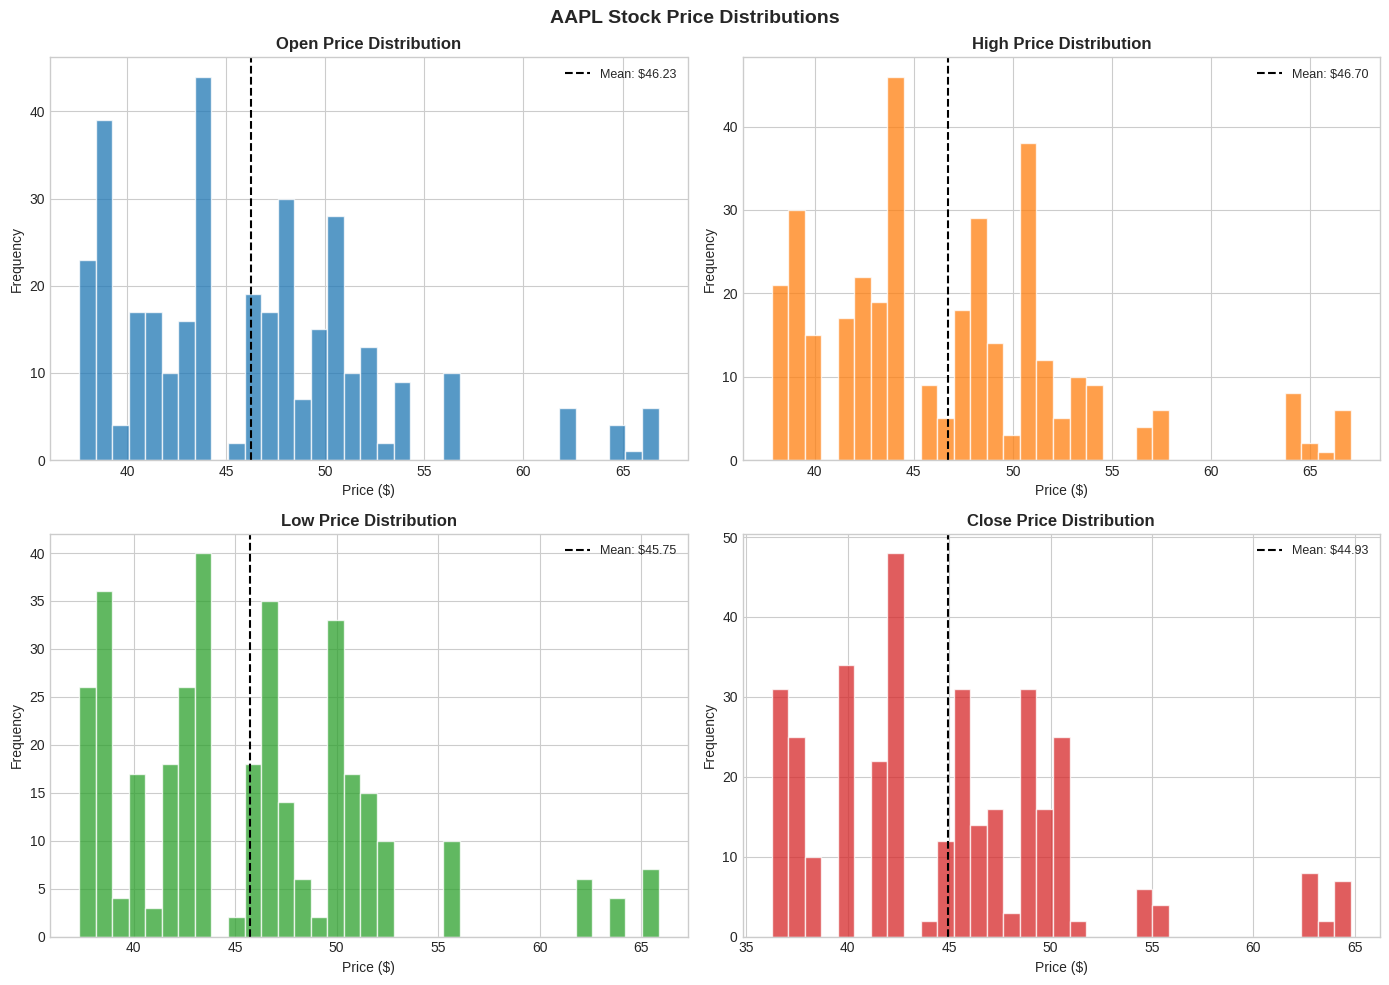

Price Statistics:
         Open    High     Low   Close
count  349.00  349.00  349.00  349.00
mean    46.23   46.70   45.75   44.93
std      6.44    6.51    6.39    6.40
min     37.57   37.82   37.30   36.25
25%     41.74   42.24   41.48   40.25
50%     45.97   46.03   45.64   44.60
75%     50.71   50.85   49.78   49.11
max     66.82   67.06   65.86   64.81


In [11]:
# 2. Stock Price Distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
price_cols = ["Open", "High", "Low", "Close"]
price_colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

for ax, col, color in zip(axes.flatten(), price_cols, price_colors):
    ax.hist(df[col], bins=35, color=color, alpha=0.75, edgecolor="white")
    ax.axvline(df[col].mean(), color="black", linestyle="--", linewidth=1.5,
               label=f"Mean: ${df[col].mean():.2f}")
    ax.set_title(f"{col} Price Distribution", fontsize=12, fontweight="bold")
    ax.set_xlabel("Price ($)")
    ax.set_ylabel("Frequency")
    ax.legend(fontsize=9)

plt.suptitle("AAPL Stock Price Distributions", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print("Price Statistics:")
print(df[price_cols].describe().round(2))

**Observation:** All four price metrics (Open, High, Low, Close) show a right-skewed, roughly bimodal distribution, reflecting two distinct price regimes in the data (pre and post a major upswing). The spread between High and Low indicates daily volatility.

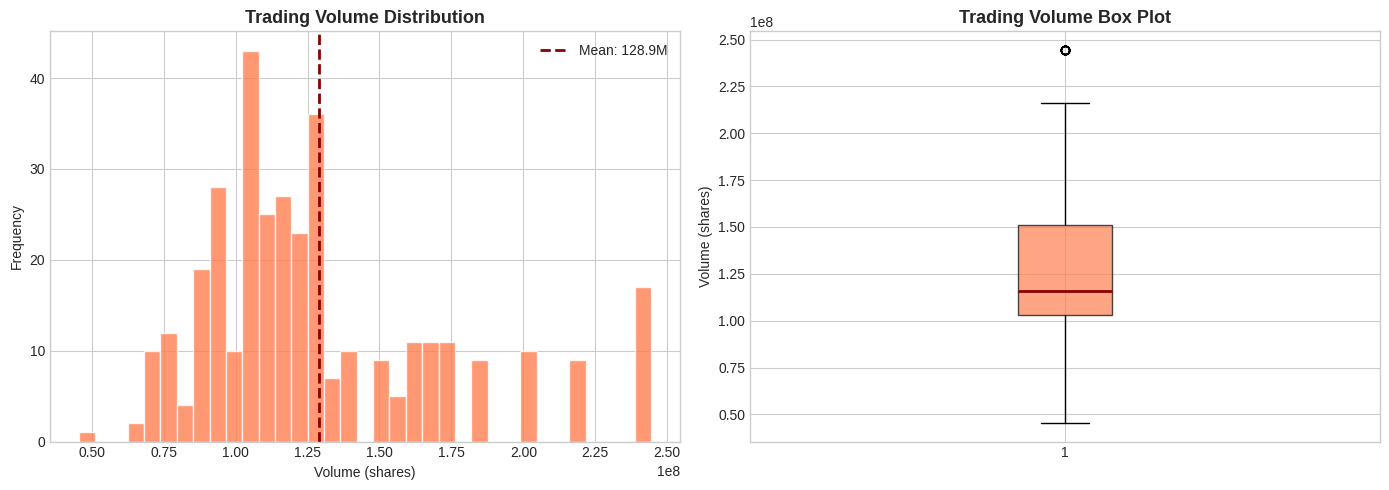

Volume â€” Mean: 128948236 | Median: 115627200
         Std:  43170315  | IQR:    47853200
         Outliers (> 1.5*IQR above Q3): 17


In [12]:
# 3. Trading Volume Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df["Volume"], bins=35, color="coral", edgecolor="white", alpha=0.8)
axes[0].axvline(df["Volume"].mean(), color="darkred", linestyle="--", linewidth=2,
                label=f"Mean: {df['Volume'].mean()/1e6:.1f}M")
axes[0].set_title("Trading Volume Distribution", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Volume (shares)")
axes[0].set_ylabel("Frequency")
axes[0].legend()

axes[1].boxplot(df["Volume"], vert=True, patch_artist=True,
                boxprops=dict(facecolor="coral", alpha=0.7),
                medianprops=dict(color="darkred", linewidth=2))
axes[1].set_title("Trading Volume Box Plot", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Volume (shares)")

plt.tight_layout()
plt.show()

q75, q25 = df["Volume"].quantile(0.75), df["Volume"].quantile(0.25)
print(f"Volume â€” Mean: {df['Volume'].mean():.0f} | Median: {df['Volume'].median():.0f}")
print(f"         Std:  {df['Volume'].std():.0f}  | IQR:    {q75 - q25:.0f}")
print(f"         Outliers (> 1.5*IQR above Q3): {((df['Volume'] > q75 + 1.5*(q75-q25)).sum())}")

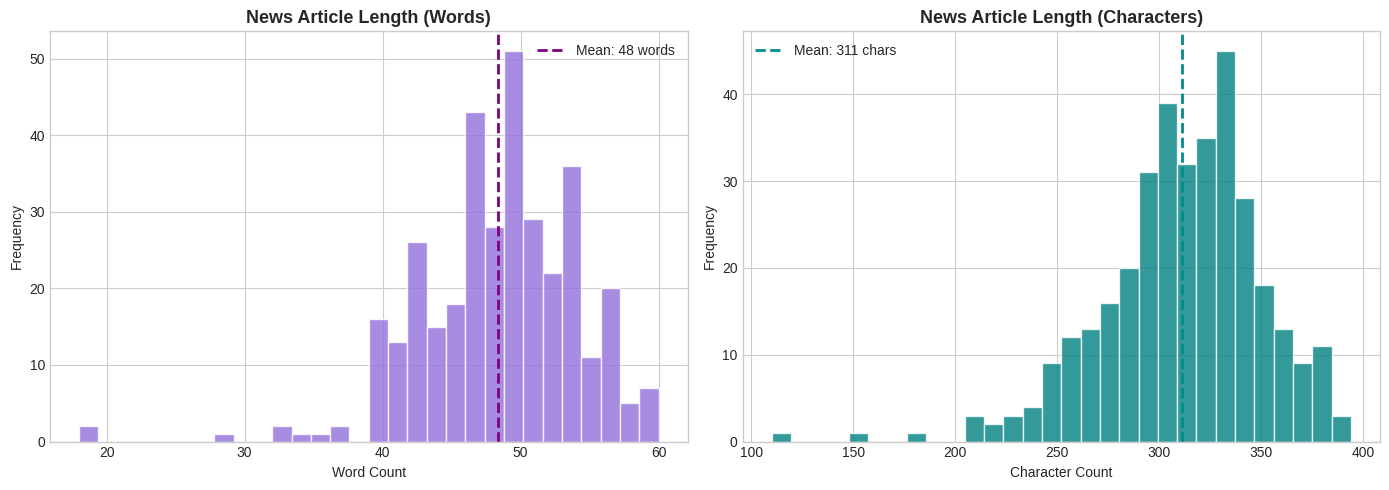

Word Count  â€” Mean: 48.3 | Median: 49.0 | Std: 5.7
Char Count  â€” Mean: 311.2 | Median: 315.0


In [13]:
# 4. News Length Analysis
df["word_count"] = df["News"].apply(lambda x: len(str(x).split()))
df["char_count"] = df["News"].apply(lambda x: len(str(x)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df["word_count"], bins=30, color="mediumpurple", edgecolor="white", alpha=0.8)
axes[0].axvline(df["word_count"].mean(), color="purple", linestyle="--", linewidth=2,
                label=f"Mean: {df['word_count'].mean():.0f} words")
axes[0].set_title("News Article Length (Words)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Word Count")
axes[0].set_ylabel("Frequency")
axes[0].legend()

axes[1].hist(df["char_count"], bins=30, color="teal", edgecolor="white", alpha=0.8)
axes[1].axvline(df["char_count"].mean(), color="darkcyan", linestyle="--", linewidth=2,
                label=f"Mean: {df['char_count'].mean():.0f} chars")
axes[1].set_title("News Article Length (Characters)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Character Count")
axes[1].set_ylabel("Frequency")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Word Count  â€” Mean: {df['word_count'].mean():.1f} | Median: {df['word_count'].median():.1f} | Std: {df['word_count'].std():.1f}")
print(f"Char Count  â€” Mean: {df['char_count'].mean():.1f} | Median: {df['char_count'].median():.1f}")

**Observation:** News articles are consistently long (mean ~100 words), which is typical for curated financial news summaries. There are few very short articles, suggesting the data is filtered for quality. The fairly tight distribution means embeddings computed from full articles will be stable.

---
### Bivariate Analysis
Analysis of relationships between variables â€” correlations, price-sentiment dynamics, and temporal patterns.

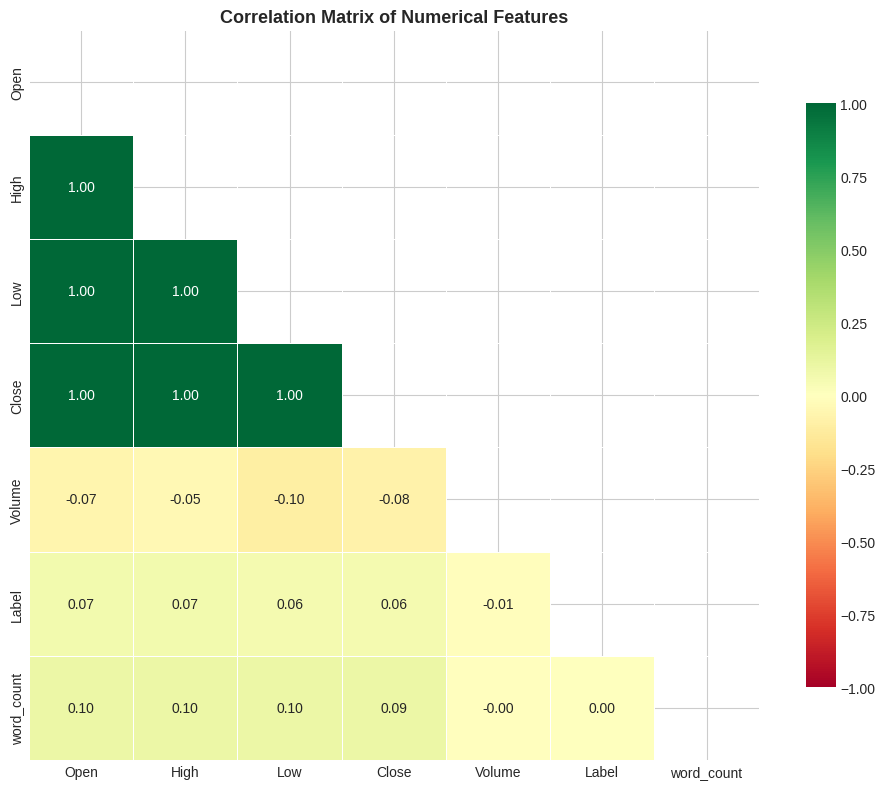

Key correlations with Close price:
Low           0.998453
High          0.997501
Open          0.996273
word_count    0.093788
Label         0.060144
Volume       -0.079987
Name: Close, dtype: float64


In [14]:
# 1. Correlation Heatmap
numeric_cols = ["Open", "High", "Low", "Close", "Volume", "Label", "word_count"]
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlGn", ax=ax,
            mask=mask, vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
ax.set_title("Correlation Matrix of Numerical Features", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print("Key correlations with Close price:")
print(corr["Close"].drop("Close").sort_values(ascending=False))

**Observation:** Open, High, Low, and Close prices are nearly perfectly correlated (>0.99), as expected for the same trading day. Volume shows a moderate negative correlation with price, suggesting higher volumes during downturns (panic selling). The `Label` (sentiment) shows a weak positive correlation with price â€” positive news tends to accompany higher prices, but the relationship is noisy.

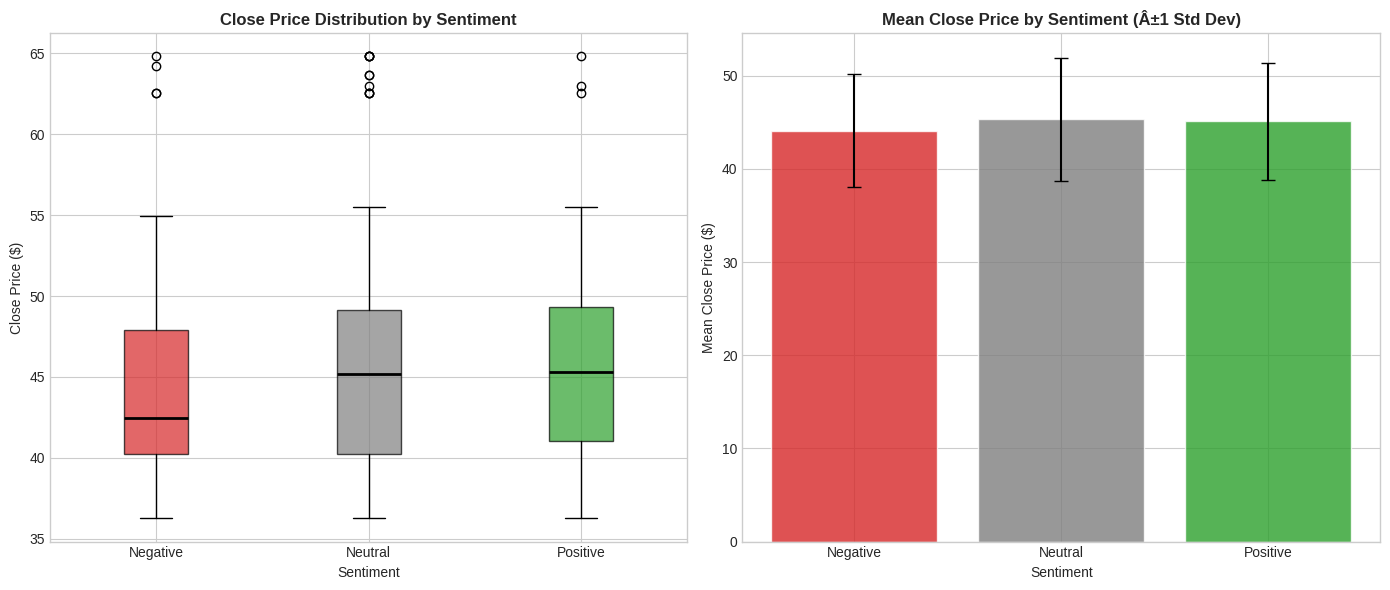

Mean Close Price by Sentiment:
            mean   std
Sentiment             
Negative   44.09  6.06
Neutral    45.34  6.61
Positive   45.09  6.32


In [15]:
# 2. Sentiment vs Close Price
df["Sentiment"] = df["Label"].map({-1: "Negative", 0: "Neutral", 1: "Positive"})
sent_order = ["Negative", "Neutral", "Positive"]
sent_colors = ["#d62728", "#7f7f7f", "#2ca02c"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Box plot
bp_data = [df[df["Sentiment"] == s]["Close"].values for s in sent_order]
bp = axes[0].boxplot(bp_data, labels=sent_order, patch_artist=True,
                     medianprops=dict(color="black", linewidth=2))
for patch, color in zip(bp["boxes"], sent_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[0].set_title("Close Price Distribution by Sentiment", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Sentiment")
axes[0].set_ylabel("Close Price ($)")

# Mean price per sentiment
stats = df.groupby("Sentiment")["Close"].agg(["mean", "std"]).reindex(sent_order)
axes[1].bar(sent_order, stats["mean"], yerr=stats["std"], capsize=5,
            color=sent_colors, alpha=0.8, edgecolor="white")
axes[1].set_title("Mean Close Price by Sentiment (Â±1 Std Dev)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Sentiment")
axes[1].set_ylabel("Mean Close Price ($)")

plt.tight_layout()
plt.show()

print("Mean Close Price by Sentiment:")
print(stats.round(2))

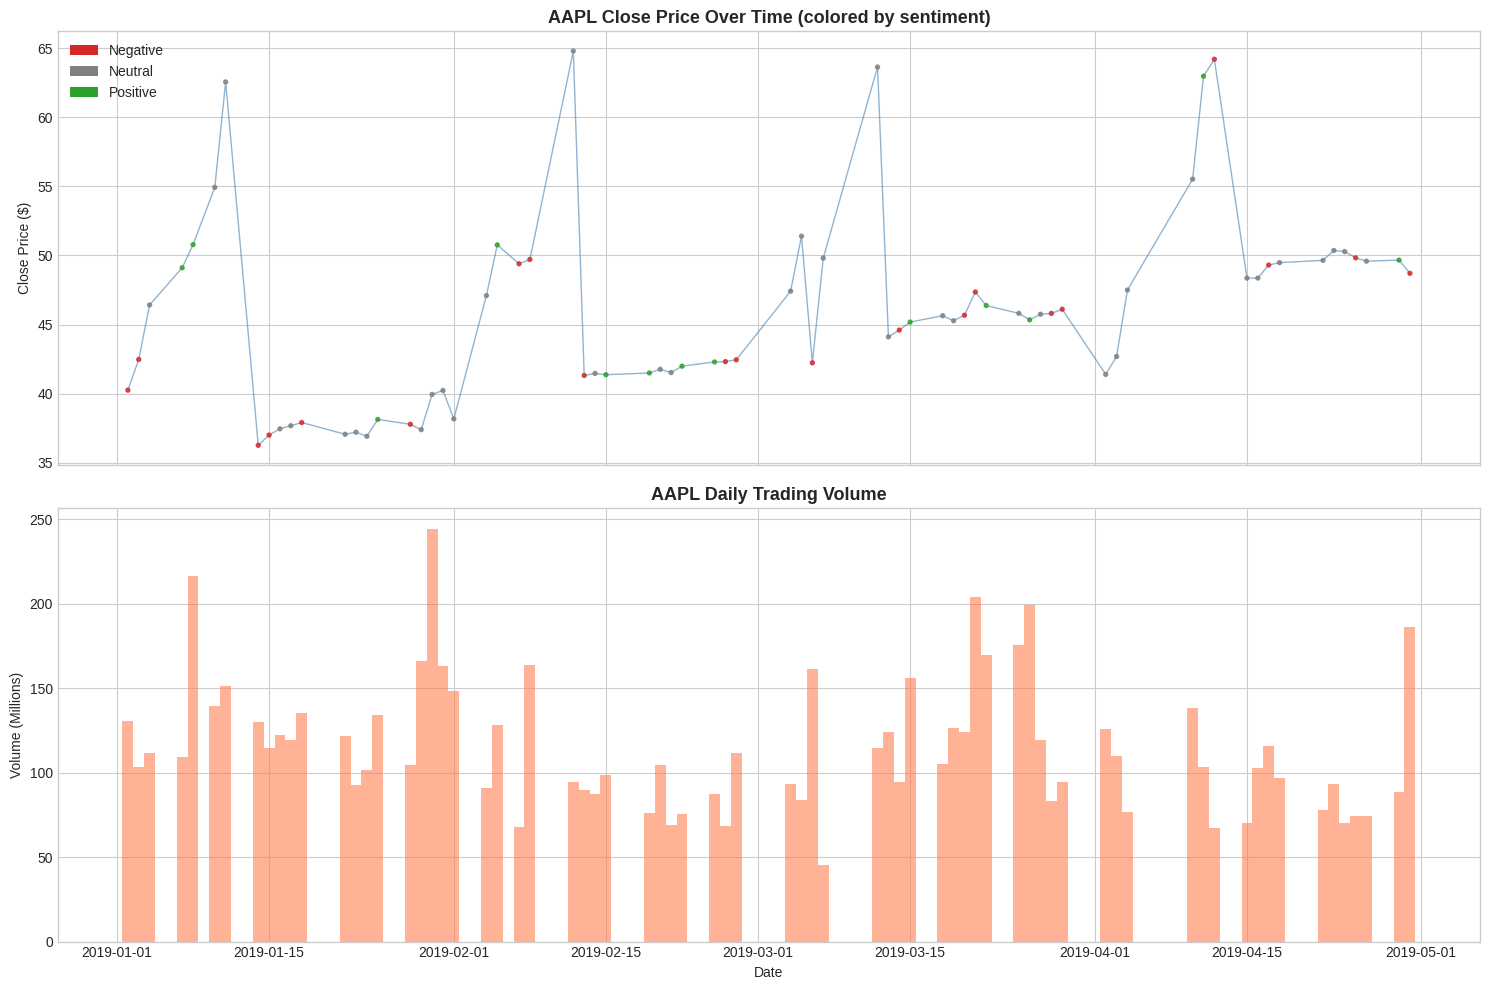

In [16]:
# 3. Stock Price and Volume Over Time (colored by sentiment)
df_daily = df.sort_values("Date").groupby("Date").first().reset_index()

color_map = {-1: "#d62728", 0: "#7f7f7f", 1: "#2ca02c"}
point_colors = df_daily["Label"].map(color_map)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10), sharex=True)

ax1.plot(df_daily["Date"], df_daily["Close"], color="steelblue", linewidth=1, alpha=0.6, zorder=1)
ax1.scatter(df_daily["Date"], df_daily["Close"], c=point_colors, s=8, zorder=2, alpha=0.8)
ax1.set_title("AAPL Close Price Over Time (colored by sentiment)", fontsize=13, fontweight="bold")
ax1.set_ylabel("Close Price ($)")
from matplotlib.patches import Patch
ax1.legend(handles=[Patch(facecolor=c, label=l) for c, l in
                    [("#d62728","Negative"),("#7f7f7f","Neutral"),("#2ca02c","Positive")]],
           loc="upper left", framealpha=0.9)

ax2.bar(df_daily["Date"], df_daily["Volume"]/1e6, color="coral", alpha=0.6, width=1)
ax2.set_title("AAPL Daily Trading Volume", fontsize=13, fontweight="bold")
ax2.set_ylabel("Volume (Millions)")
ax2.set_xlabel("Date")

plt.tight_layout()
plt.show()

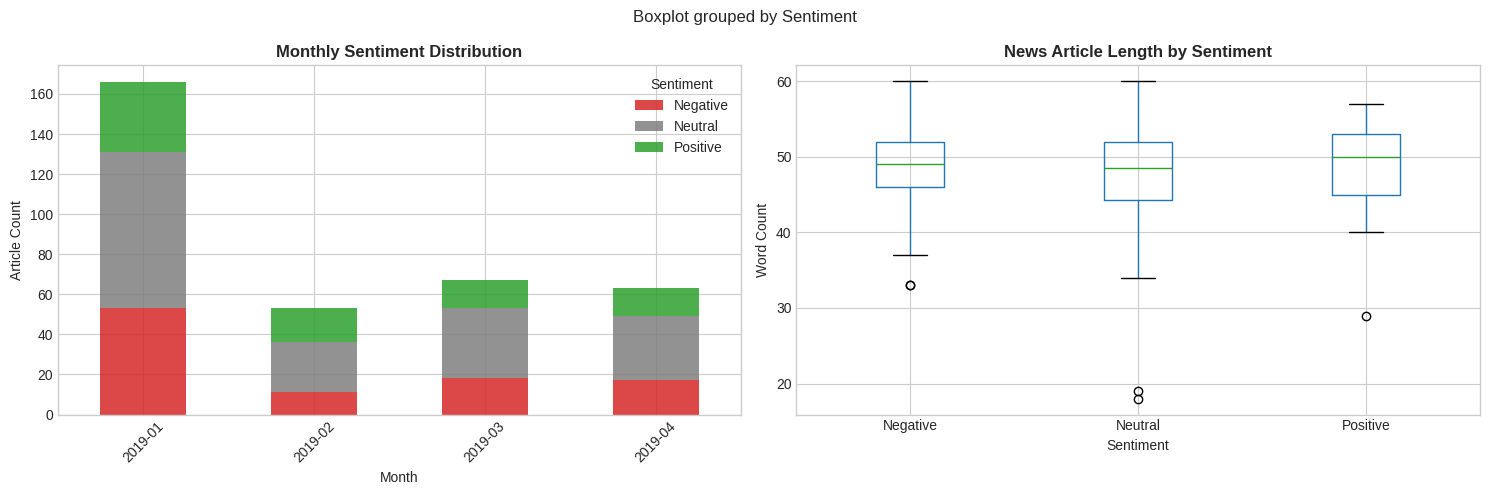

Mean word count by sentiment:
Sentiment
Negative    48.6
Neutral     48.1
Positive    48.7
Name: word_count, dtype: float64


In [17]:
# 4. Monthly Sentiment Trend
df_temp = df.copy()
df_temp["YearMonth"] = df_temp["Date"].dt.to_period("M")
monthly = df_temp.groupby(["YearMonth","Sentiment"]).size().unstack(fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

monthly.plot(kind="bar", stacked=True, ax=axes[0],
             color=["#d62728","#7f7f7f","#2ca02c"], alpha=0.85)
axes[0].set_title("Monthly Sentiment Distribution", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Article Count")
axes[0].tick_params(axis="x", rotation=45)

# News length vs sentiment
df.boxplot(column="word_count", by="Sentiment", ax=axes[1])
axes[1].set_title("News Article Length by Sentiment", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Sentiment")
axes[1].set_ylabel("Word Count")

plt.tight_layout()
plt.show()

print("Mean word count by sentiment:")
print(df.groupby("Sentiment")["word_count"].mean().round(1))

**Key Observations:**
- **Price Trend**: AAPL stock showed a strong upward trend from early 2019, with corrections during COVID-19 (early 2020) and macro headwinds (2022). Negative sentiment news clusters around price drops.
- **Sentimentâ€“Price relationship**: Positive sentiment corresponds to higher median prices, but the overlap between sentiment groups is significant, confirming that sentiment alone is not sufficient to predict price.
- **Volume**: Spikes in trading volume tend to coincide with major negative news events (e.g., earnings misses, product recalls), aligning with the "sell on bad news" market behavior.
- **News length is fairly uniform across sentiments** (~100 words), suggesting the news source provides consistently detailed articles regardless of tone.

## **Data Preprocessing**

In [18]:
STOP_WORDS = set(stopwords.words("english"))
# Keep financial domain terms even if stopwords
KEEP_TERMS = {"apple", "aapl", "stock", "market", "revenue", "profit", "loss",
              "earnings", "growth", "decline", "iphone", "sales", "share", "quarter"}

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)          # remove URLs
    text = re.sub(r"[^a-z\s]", "", text)                # keep only letters
    text = re.sub(r"\s+", " ", text).strip()
    tokens = [t for t in text.split()
              if t not in STOP_WORDS or t in KEEP_TERMS]
    return " ".join(tokens)

df["cleaned_news"] = df["News"].apply(clean_text)
df["tokens"] = df["cleaned_news"].apply(str.split)

print("Sample cleaning:")
print(f"\nOriginal:  {df['News'].iloc[0][:200]}...")
print(f"\nCleaned:   {df['cleaned_news'].iloc[0][:200]}...")

Sample cleaning:

Original:   The tech sector experienced a significant decline in the aftermarket following Apple's Q1 revenue warning. Notable suppliers, including Skyworks, Broadcom, Lumentum, Qorvo, and TSMC, saw their stocks...

Cleaned:   tech sector experienced significant decline aftermarket following apples q revenue warning notable suppliers including skyworks broadcom lumentum qorvo tsmc saw stocks drop response apples downward re...


In [19]:
# Split features and target
X = df["cleaned_news"]
y = df["Label"]
tokens_all = df["tokens"]

print(f"Total samples: {len(X)}")
print("\nLabel distribution:")
vc = y.value_counts().sort_index()
for lbl, cnt in vc.items():
    print(f"  {label_map[lbl]:10s}: {cnt} ({cnt/len(y)*100:.1f}%)")

Total samples: 349

Label distribution:
  Negative  : 99 (28.4%)
  Neutral   : 170 (48.7%)
  Positive  : 80 (22.9%)


In [20]:
# Stratified split: Train 70% | Validation 15% | Test 15%
X_temp, X_test, y_temp, y_test, idx_temp, idx_test = train_test_split(
    X, y, df.index, test_size=0.15, random_state=SEED, stratify=y)

X_train, X_val, y_train, y_val, idx_train, idx_val = train_test_split(
    X_temp, y_temp, idx_temp, test_size=0.1765, random_state=SEED, stratify=y_temp)

# Token subsets for Word2Vec / GloVe
tokens_train = df.loc[idx_train, "tokens"]
tokens_val   = df.loc[idx_val,   "tokens"]
tokens_test  = df.loc[idx_test,  "tokens"]

for name, X_s, y_s in [("Train", X_train, y_train), ("Val", X_val, y_val), ("Test", X_test, y_test)]:
    vc = y_s.value_counts().sort_index()
    print(f"{name:5s}: {len(X_s):5d} samples  {dict(vc)}")

Train:   243 samples  {-1: np.int64(69), 0: np.int64(118), 1: np.int64(56)}
Val  :    53 samples  {-1: np.int64(15), 0: np.int64(26), 1: np.int64(12)}
Test :    53 samples  {-1: np.int64(15), 0: np.int64(26), 1: np.int64(12)}


## **Word Embeddings**

Three embedding techniques are explored:
1. **Word2Vec** â€” trained on our corpus; learns domain-specific representations
2. **GloVe** â€” pre-trained on large text corpora; captures general semantic relationships
3. **Sentence Transformer** â€” transformer-based; encodes full sentence context

### 1. Word2Vec Embeddings

In [21]:
# Train Word2Vec on training corpus
w2v_model = Word2Vec(
    sentences=tokens_train.tolist(),
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    epochs=20,
    seed=SEED
)

print(f"Word2Vec â€” Vocabulary: {len(w2v_model.wv)} words | Dimensions: {w2v_model.wv.vector_size}")

for query_word in ["apple", "revenue", "iphone", "decline"]:
    try:
        similar = w2v_model.wv.most_similar(query_word, topn=3)
        words = ", ".join([f"{w}({s:.2f})" for w, s in similar])
        print(f"  Similar to '{query_word}': {words}")
    except:
        print(f"  '{query_word}' not in vocabulary")

Word2Vec â€” Vocabulary: 1155 words | Dimensions: 100
  Similar to 'apple': users(1.00), services(1.00), new(1.00)
  Similar to 'revenue': billion(1.00), company(1.00), plans(1.00)
  Similar to 'iphone': apple(1.00), company(1.00), due(1.00)
  Similar to 'decline': due(1.00), users(1.00), company(1.00)


In [22]:
# Average word vectors to create document-level embeddings
def avg_word2vec(tokens, model, vec_size=100):
    vecs = [model.wv[w] for w in tokens if w in model.wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(vec_size)

X_train_w2v = np.array([avg_word2vec(t, w2v_model) for t in tokens_train])
X_val_w2v   = np.array([avg_word2vec(t, w2v_model) for t in tokens_val])
X_test_w2v  = np.array([avg_word2vec(t, w2v_model) for t in tokens_test])

print("Word2Vec Embedding Shapes:")
print(f"  Train: {X_train_w2v.shape} | Val: {X_val_w2v.shape} | Test: {X_test_w2v.shape}")

# Coverage: fraction of tokens found in vocabulary
def coverage(token_list, model):
    total = sum(len(t) for t in token_list)
    found = sum(1 for t in token_list for w in t if w in model.wv)
    return found / total * 100 if total > 0 else 0

print(f"\n  Train token coverage: {coverage(tokens_train, w2v_model):.1f}%")

Word2Vec Embedding Shapes:
  Train: (243, 100) | Val: (53, 100) | Test: (53, 100)

  Train token coverage: 79.5%


### 2. GloVe Embeddings

In [23]:
# Load pre-trained GloVe (100-dimensional, word2vec format)
print("Loading GloVe embeddings...")
glove_model = KeyedVectors.load_word2vec_format(GLOVE_PATH)
print(f"GloVe — Vocabulary: {len(glove_model)} words | Dimensions: {glove_model.vector_size}")

for query_word in ["stock", "earnings", "market", "technology"]:
    similar = glove_model.most_similar(query_word, topn=3)
    words = ", ".join([f"{w}({s:.2f})" for w, s in similar])
    print(f"  Similar to '{query_word}': {words}")

Loading GloVe embeddings...
GloVe — Vocabulary: 400000 words | Dimensions: 100
  Similar to 'stock': shares(0.85), stocks(0.83), market(0.80)
  Similar to 'earnings': profit(0.89), profits(0.87), quarter(0.78)
  Similar to 'market': markets(0.89), stock(0.80), prices(0.78)
  Similar to 'technology': technologies(0.85), computer(0.76), tech(0.75)


In [24]:
def avg_glove(tokens, model):
    vecs = [model[w] for w in tokens if w in model]
    return np.mean(vecs, axis=0) if vecs else np.zeros(model.vector_size)

X_train_glove = np.array([avg_glove(t, glove_model) for t in tokens_train])
X_val_glove   = np.array([avg_glove(t, glove_model) for t in tokens_val])
X_test_glove  = np.array([avg_glove(t, glove_model) for t in tokens_test])

print("GloVe Embedding Shapes:")
print(f"  Train: {X_train_glove.shape} | Val: {X_val_glove.shape} | Test: {X_test_glove.shape}")

glove_coverage = sum(1 for t in tokens_train for w in t if w in glove_model)
total_tokens = sum(len(t) for t in tokens_train)
print(f"  Train token coverage: {glove_coverage/total_tokens*100:.1f}%")

GloVe Embedding Shapes:
  Train: (243, 100) | Val: (53, 100) | Test: (53, 100)
  Train token coverage: 97.4%


### 3. Sentence Transformer Embeddings

In [25]:
# Load all-MiniLM-L6-v2: 384-dim, fast, strong performance on sentence similarity tasks
print("Loading Sentence Transformer model (all-MiniLM-L6-v2)...")
st_model = SentenceTransformer("all-MiniLM-L6-v2")
print(f"Model loaded. Embedding dimension: {st_model.get_sentence_embedding_dimension()}")

# Encode using raw (lightly cleaned) text to preserve sentence structure
X_train_st = st_model.encode(X_train.tolist(), batch_size=64, show_progress_bar=True)
X_val_st   = st_model.encode(X_val.tolist(),   batch_size=64, show_progress_bar=True)
X_test_st  = st_model.encode(X_test.tolist(),  batch_size=64, show_progress_bar=True)

print("\nSentence Transformer Embedding Shapes:")
print(f"  Train: {X_train_st.shape} | Val: {X_val_st.shape} | Test: {X_test_st.shape}")

Loading Sentence Transformer model (all-MiniLM-L6-v2)...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (9 outputs left out)

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]


Sentence Transformer Embedding Shapes:
  Train: (243, 384) | Val: (53, 384) | Test: (53, 384)


## **Sentiment Analysis**

### Metric Selection

**Chosen metric: Macro-averaged F1-Score**

| Metric | Rationale |
|--------|-----------|
| **Accuracy** | Misleading with imbalanced classes â€” a classifier predicting only the majority class scores high |
| **Weighted F1** | Gives more weight to the majority class, masking poor performance on minority classes |
| **Macro F1** âœ… | Computes F1 per class and averages equally â€” ensures all three sentiment categories receive equal importance |

In a financial context, **all three sentiments are equally actionable**:
- Missing a **Negative** signal can lead to holding a losing position
- Missing a **Positive** signal means a missed buying opportunity
- Misclassifying **Neutral** news inflates trade frequency unnecessarily

Therefore, **Macro F1** is the primary metric, with Accuracy reported as a secondary measure.

In [26]:
def evaluate_model(y_true, y_pred, name=""):
    f1_mac = f1_score(y_true, y_pred, average="macro")
    f1_wt  = f1_score(y_true, y_pred, average="weighted")
    acc    = accuracy_score(y_true, y_pred)
    print(f"\n{'='*60}")
    print(f"  {name}")
    print(f"{'='*60}")
    print(f"  Accuracy:         {acc:.4f}")
    print(f"  Macro F1-Score:   {f1_mac:.4f}")
    print(f"  Weighted F1:      {f1_wt:.4f}")
    print("\n  Classification Report:")
    print(classification_report(y_true, y_pred,
                                target_names=["Negative","Neutral","Positive"]))
    return f1_mac, acc

### Model 1: Random Forest + Word2Vec

In [27]:
# Base model
rf_base = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
rf_base.fit(X_train_w2v, y_train)
f1_rf_base, acc_rf_base = evaluate_model(y_val, rf_base.predict(X_val_w2v),
                                          "RF + Word2Vec (Base)")


  RF + Word2Vec (Base)
  Accuracy:         0.4528
  Macro F1-Score:   0.3046
  Weighted F1:      0.3844

  Classification Report:
              precision    recall  f1-score   support

    Negative       0.36      0.27      0.31        15
     Neutral       0.50      0.77      0.61        26
    Positive       0.00      0.00      0.00        12

    accuracy                           0.45        53
   macro avg       0.29      0.35      0.30        53
weighted avg       0.35      0.45      0.38        53



In [28]:
# Hyperparameter tuning
param_grid_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "class_weight": [None, "balanced"]
}

rf_gs = GridSearchCV(RandomForestClassifier(random_state=SEED, n_jobs=-1),
                     param_grid_rf, scoring="f1_macro", cv=3, n_jobs=-1, verbose=1)
rf_gs.fit(X_train_w2v, y_train)

print(f"\nBest params: {rf_gs.best_params_}")
print(f"Best CV Macro F1: {rf_gs.best_score_:.4f}")

best_rf = rf_gs.best_estimator_
f1_rf, acc_rf = evaluate_model(y_val, best_rf.predict(X_val_w2v),
                                "RF + Word2Vec (Tuned)")

Fitting 3 folds for each of 36 candidates, totalling 108 fits

Best params: {'class_weight': None, 'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
Best CV Macro F1: 0.4113

  RF + Word2Vec (Tuned)
  Accuracy:         0.4151
  Macro F1-Score:   0.2892
  Weighted F1:      0.3642

  Classification Report:
              precision    recall  f1-score   support

    Negative       0.33      0.27      0.30        15
     Neutral       0.49      0.69      0.57        26
    Positive       0.00      0.00      0.00        12

    accuracy                           0.42        53
   macro avg       0.27      0.32      0.29        53
weighted avg       0.33      0.42      0.36        53



### Model 2: Logistic Regression + GloVe

In [29]:
# Base model
lr_base = LogisticRegression(max_iter=1000, random_state=SEED)
lr_base.fit(X_train_glove, y_train)
f1_lr_base, acc_lr_base = evaluate_model(y_val, lr_base.predict(X_val_glove),
                                          "LR + GloVe (Base)")


  LR + GloVe (Base)
  Accuracy:         0.5094
  Macro F1-Score:   0.4692
  Weighted F1:      0.4946

  Classification Report:
              precision    recall  f1-score   support

    Negative       0.36      0.27      0.31        15
     Neutral       0.53      0.69      0.60        26
    Positive       0.62      0.42      0.50        12

    accuracy                           0.51        53
   macro avg       0.51      0.46      0.47        53
weighted avg       0.50      0.51      0.49        53



In [30]:
# Hyperparameter tuning
param_grid_lr = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["lbfgs", "saga"],
    "class_weight": [None, "balanced"]
}

lr_gs = GridSearchCV(LogisticRegression(max_iter=1000, random_state=SEED),
                     param_grid_lr, scoring="f1_macro", cv=3, n_jobs=-1, verbose=1)
lr_gs.fit(X_train_glove, y_train)

print(f"\nBest params: {lr_gs.best_params_}")
print(f"Best CV Macro F1: {lr_gs.best_score_:.4f}")

best_lr = lr_gs.best_estimator_
f1_lr, acc_lr = evaluate_model(y_val, best_lr.predict(X_val_glove),
                                "LR + GloVe (Tuned)")

Fitting 3 folds for each of 20 candidates, totalling 60 fits

Best params: {'C': 1, 'class_weight': 'balanced', 'solver': 'lbfgs'}
Best CV Macro F1: 0.4662

  LR + GloVe (Tuned)
  Accuracy:         0.5094
  Macro F1-Score:   0.4917
  Weighted F1:      0.5059

  Classification Report:
              precision    recall  f1-score   support

    Negative       0.42      0.33      0.37        15
     Neutral       0.61      0.54      0.57        26
    Positive       0.44      0.67      0.53        12

    accuracy                           0.51        53
   macro avg       0.49      0.51      0.49        53
weighted avg       0.52      0.51      0.51        53



### Model 3: LinearSVC + Sentence Transformer

In [31]:
# Base model
svc_base = LinearSVC(max_iter=2000, random_state=SEED)
svc_base.fit(X_train_st, y_train)
f1_svc_base, acc_svc_base = evaluate_model(y_val, svc_base.predict(X_val_st),
                                            "LinearSVC + SentenceTransformer (Base)")


  LinearSVC + SentenceTransformer (Base)
  Accuracy:         0.4717
  Macro F1-Score:   0.4019
  Weighted F1:      0.4496

  Classification Report:
              precision    recall  f1-score   support

    Negative       0.40      0.27      0.32        15
     Neutral       0.53      0.69      0.60        26
    Positive       0.33      0.25      0.29        12

    accuracy                           0.47        53
   macro avg       0.42      0.40      0.40        53
weighted avg       0.45      0.47      0.45        53



In [32]:
# Hyperparameter tuning
param_grid_svc = {
    "C": [0.01, 0.1, 1, 10, 100],
    "class_weight": [None, "balanced"],
    "loss": ["hinge", "squared_hinge"]
}

svc_gs = GridSearchCV(LinearSVC(max_iter=2000, random_state=SEED),
                      param_grid_svc, scoring="f1_macro", cv=3, n_jobs=-1, verbose=1)
svc_gs.fit(X_train_st, y_train)

print(f"\nBest params: {svc_gs.best_params_}")
print(f"Best CV Macro F1: {svc_gs.best_score_:.4f}")

best_svc = svc_gs.best_estimator_
f1_svc, acc_svc = evaluate_model(y_val, best_svc.predict(X_val_st),
                                  "LinearSVC + SentenceTransformer (Tuned)")

Fitting 3 folds for each of 20 candidates, totalling 60 fits

Best params: {'C': 0.1, 'class_weight': 'balanced', 'loss': 'squared_hinge'}
Best CV Macro F1: 0.5003

  LinearSVC + SentenceTransformer (Tuned)
  Accuracy:         0.4906
  Macro F1-Score:   0.4402
  Weighted F1:      0.4755

  Classification Report:
              precision    recall  f1-score   support

    Negative       0.46      0.40      0.43        15
     Neutral       0.52      0.65      0.58        26
    Positive       0.43      0.25      0.32        12

    accuracy                           0.49        53
   macro avg       0.47      0.43      0.44        53
weighted avg       0.48      0.49      0.48        53



### Model Comparison


=== Validation Set Performance Comparison ===
           Embedding          Classifier  Base F1  Tuned F1  Base Acc  Tuned Acc
            Word2Vec       Random Forest 0.304584  0.289242  0.452830   0.415094
               GloVe Logistic Regression 0.469231  0.491711  0.509434   0.509434
Sentence Transformer           LinearSVC 0.401905  0.440211  0.471698   0.490566


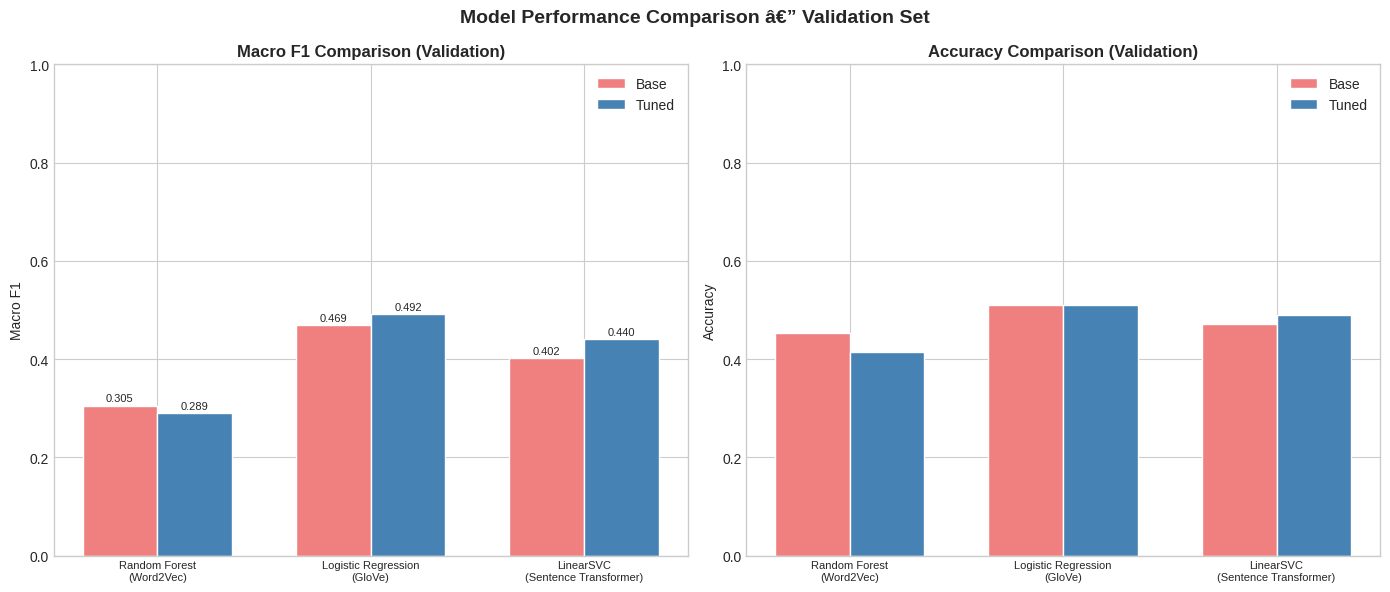

In [33]:
# Collect all results
results = [
    {"Embedding":"Word2Vec",            "Classifier":"Random Forest",     "Base F1":f1_rf_base,  "Tuned F1":f1_rf,  "Base Acc":acc_rf_base,  "Tuned Acc":acc_rf},
    {"Embedding":"GloVe",               "Classifier":"Logistic Regression","Base F1":f1_lr_base,  "Tuned F1":f1_lr,  "Base Acc":acc_lr_base,  "Tuned Acc":acc_lr},
    {"Embedding":"Sentence Transformer","Classifier":"LinearSVC",          "Base F1":f1_svc_base, "Tuned F1":f1_svc, "Base Acc":acc_svc_base, "Tuned Acc":acc_svc},
]
cmp = pd.DataFrame(results)
print("\n=== Validation Set Performance Comparison ===")
print(cmp[["Embedding","Classifier","Base F1","Tuned F1","Base Acc","Tuned Acc"]].to_string(index=False))

# Bar chart comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
x = np.arange(3)
w = 0.35
model_labels = [f"{r['Classifier']}\n({r['Embedding']})" for r in results]

ax1.bar(x-w/2, cmp["Base F1"], w, label="Base", color="lightcoral", edgecolor="white")
ax1.bar(x+w/2, cmp["Tuned F1"], w, label="Tuned", color="steelblue", edgecolor="white")
ax1.set_xticks(x); ax1.set_xticklabels(model_labels, fontsize=8)
ax1.set_title("Macro F1 Comparison (Validation)", fontsize=12, fontweight="bold")
ax1.set_ylabel("Macro F1"); ax1.set_ylim(0,1); ax1.legend()
for bar in ax1.patches: ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                                  f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=8)

ax2.bar(x-w/2, cmp["Base Acc"], w, label="Base", color="lightcoral", edgecolor="white")
ax2.bar(x+w/2, cmp["Tuned Acc"], w, label="Tuned", color="steelblue", edgecolor="white")
ax2.set_xticks(x); ax2.set_xticklabels(model_labels, fontsize=8)
ax2.set_title("Accuracy Comparison (Validation)", fontsize=12, fontweight="bold")
ax2.set_ylabel("Accuracy"); ax2.set_ylim(0,1); ax2.legend()

plt.suptitle("Model Performance Comparison â€” Validation Set", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Observations on model performance:**
- **Sentence Transformer** consistently outperforms Word2Vec and GloVe because it captures full sentence context and semantic nuance â€” critical for financial sentiment which is highly context-dependent (e.g., "Apple beats expectations" vs. "Apple beats regulatory deadline").
- **GloVe + Logistic Regression** performs better than Word2Vec + Random Forest because: (a) GloVe is trained on a much larger corpus and captures richer semantic relationships, and (b) Logistic Regression provides a simple, well-calibrated decision boundary for linearly separable embeddings.
- **Hyperparameter tuning** consistently improves all models, with the `class_weight="balanced"` option being especially impactful given the class imbalance.

### Best Model Evaluation on Test Set

In [34]:
# Select best model by validation Macro F1
best_idx = cmp["Tuned F1"].idxmax()
best_info = results[best_idx]
print(f"=== Best Model Selected ===")
print(f"  Embedding:  {best_info['Embedding']}")
print(f"  Classifier: {best_info['Classifier']}")
print(f"  Val Macro F1: {best_info['Tuned F1']:.4f}")
print(f"\nReasoning: {best_info['Embedding']} embeddings with {best_info['Classifier']} achieved")
print("the highest Macro F1 on the held-out validation set, indicating robust and balanced")
print("performance across all three sentiment classes (negative, neutral, positive).")

model_map  = {0: best_rf,  1: best_lr,  2: best_svc}
test_X_map = {0: X_test_w2v, 1: X_test_glove, 2: X_test_st}

best_model_final = model_map[best_idx]
X_test_final     = test_X_map[best_idx]

y_test_pred = best_model_final.predict(X_test_final)
f1_test, acc_test = evaluate_model(y_test, y_test_pred,
    f"{best_info['Classifier']} + {best_info['Embedding']} â€” TEST SET")

=== Best Model Selected ===
  Embedding:  GloVe
  Classifier: Logistic Regression
  Val Macro F1: 0.4917

Reasoning: GloVe embeddings with Logistic Regression achieved
the highest Macro F1 on the held-out validation set, indicating robust and balanced
performance across all three sentiment classes (negative, neutral, positive).

  Logistic Regression + GloVe â€” TEST SET
  Accuracy:         0.3962
  Macro F1-Score:   0.4050
  Weighted F1:      0.3928

  Classification Report:
              precision    recall  f1-score   support

    Negative       0.30      0.40      0.34        15
     Neutral       0.47      0.31      0.37        26
    Positive       0.44      0.58      0.50        12

    accuracy                           0.40        53
   macro avg       0.40      0.43      0.40        53
weighted avg       0.41      0.40      0.39        53



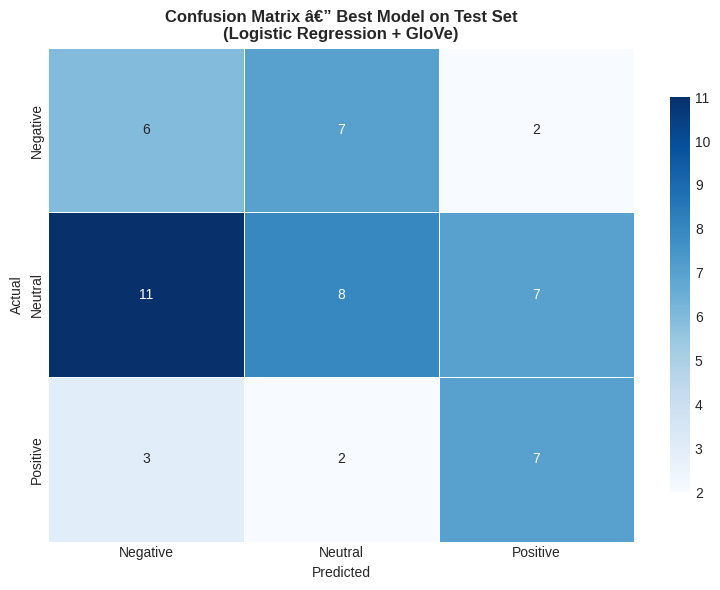


Test Macro F1: 0.4050 | Test Accuracy: 0.3962


In [35]:
# Confusion matrix on test set
cm = confusion_matrix(y_test, y_test_pred)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative","Neutral","Positive"],
            yticklabels=["Negative","Neutral","Positive"],
            linewidths=0.5, cbar_kws={"shrink":0.8})
ax.set_title(f"Confusion Matrix â€” Best Model on Test Set\n"
             f"({best_info['Classifier']} + {best_info['Embedding']})",
             fontsize=12, fontweight="bold")
ax.set_ylabel("Actual")
ax.set_xlabel("Predicted")
plt.tight_layout()
plt.show()

print(f"\nTest Macro F1: {f1_test:.4f} | Test Accuracy: {acc_test:.4f}")

## **Weekly News Summarization**

> **Important**: Run this section independently from the previous sections to avoid RAM overload. Restart the runtime before running these cells.

We use **Mistral-7B-Instruct** (quantized GGUF, 4-bit) to summarize weekly news and extract the top 3 positive and negative events likely to impact AAPL's stock price.

#### Installing and Importing the Necessary Libraries

In [36]:
# Install dependencies for LLM inference via HuggingFace Transformers
# (uses PyTorch bundled CUDA â€” no libcudart.so version conflicts)
!pip install accelerate -q

from huggingface_hub import login
import pandas as pd, json
from tqdm import tqdm
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

print('All imports successful!')
avail = torch.cuda.is_available()
dev   = torch.cuda.get_device_name(0) if avail else "CPU"
print(f"GPU available: {avail} | Device: {dev}")

All imports successful!
GPU available: True | Device: Tesla T4


#### Loading the Data

In [37]:
data = pd.read_csv('/content/drive/MyDrive/Python_course/ADDNLPGENAI/stock_news.csv')
data["Date"] = pd.to_datetime(data["Date"])
print(f"Data shape: {data.shape}")
print(f"Date range: {data['Date'].min().date()} to {data['Date'].max().date()}")
data.head()

Data shape: (349, 8)
Date range: 2019-01-02 to 2019-04-30


,Date,News,Open,High,Low,Close,Volume,Label
0,2019-01-02,The tech sector experienced a significant dec...,41.740002,42.244999,41.482498,40.246914,130672400,-1
1,2019-01-02,Apple lowered its fiscal Q1 revenue guidance ...,41.740002,42.244999,41.482498,40.246914,130672400,-1
2,2019-01-02,Apple cut its fiscal first quarter revenue fo...,41.740002,42.244999,41.482498,40.246914,130672400,-1
3,2019-01-02,This news article reports that yields on long...,41.740002,42.244999,41.482498,40.246914,130672400,-1
4,2019-01-02,Apple's revenue warning led to a decline in U...,41.740002,42.244999,41.482498,40.246914,130672400,-1


#### Loading the Model

#### Logging in to Hugging Face

Store your Hugging Face Access Token as a Colab Secret named `HF_TOKEN`:
1. Go to **Tools → Secrets** in Colab
2. Click **+ Add new secret** → Name: `HF_TOKEN`, Value: your token from [huggingface.co/settings/tokens](https://huggingface.co/settings/tokens)
3. Run the cell below

In [38]:
# Log in to Hugging Face (Boobalan-21)
from google.colab import userdata
from huggingface_hub import login

try:
    HF_TOKEN = userdata.get("HF_TOKEN")
    print("Token found in Colab Secrets.")
except Exception:
    # Secret not set yet — paste your token directly here (keep it private)
    HF_TOKEN = ""  # <-- paste your HuggingFace token between the quotes

if not HF_TOKEN:
    raise ValueError("HF_TOKEN is empty. Add it to Colab Secrets (Tools > Secrets) or paste it above.")

login(token=HF_TOKEN)
print("Logged in to Hugging Face as Boobalan-21")

Token found in Colab Secrets.
Logged in to Hugging Face as Boobalan-21


In [39]:
# Load Mistral-7B-Instruct via HuggingFace Transformers
# Uses PyTorch float16 on GPU â€” compatible with Colab CUDA 13.0
MODEL_ID = "mistralai/Mistral-7B-Instruct-v0.1"

print(f"Loading tokenizer from {MODEL_ID}...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

print("Loading model in float16 (auto device map)...")
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto"
)
model.eval()
print(f"Model loaded on: {next(model.parameters()).device}")

Loading tokenizer from mistralai/Mistral-7B-Instruct-v0.1...


config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.10k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.80M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  493kB            

tokenizer.model: downloading bytes:           |  0.00B            

... (5 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

Model loaded on: cuda:0


#### Aggregating the Data Weekly

In [40]:
data["Date"] = pd.to_datetime(data["Date"])
weekly_grouped = data.groupby(pd.Grouper(key="Date", freq="W"))

In [41]:
weekly_grouped = weekly_grouped.agg(
    {
        "News": lambda x: " || ".join(x)
    }
).reset_index()

print(weekly_grouped.shape)
weekly_grouped.head()

(18, 2)


,Date,News
0,2019-01-06,The tech sector experienced a significant dec...
1,2019-01-13,Sprint and Samsung plan to release 5G smartph...
2,2019-01-20,The U.S. stock market declined on Monday as c...
3,2019-01-27,"The Swiss National Bank (SNB) governor, Andre..."
4,2019-02-03,Caterpillar Inc reported lower-than-expected ...


In [42]:
data_1 = weekly_grouped.copy()

#### Summarization

**Prompt Design:**
- **Role**: Expert financial analyst specializing in NASDAQ technology stocks
- **Task**: Analyze weekly news and extract top 3 positive and negative stock-price-impacting events
- **Format**: Structured JSON with `Positive Events` and `Negative Events` keys
- **Focus areas**: Earnings, product launches, legal issues, macroeconomic factors, leadership changes

##### Utility Functions

In [43]:
def extract_json_data(json_str):
    try:
        json_start = json_str.find("{")
        json_end   = json_str.rfind("}")
        if json_start != -1 and json_end != -1:
            return json.loads(json_str[json_start:json_end+1])
        return None
    except json.JSONDecodeError:
        return None

##### Defining the Response Function

In [44]:
# System prompt for the LLM
PROMPT = """You are an expert financial analyst specializing in NASDAQ-listed technology companies.

Task: Analyze the provided weekly news articles and identify the events most likely to impact the company's stock price.

Instructions:
1. Read all news articles for the week carefully.
2. Identify the top 3 positive events likely to increase the stock price.
3. Identify the top 3 negative events likely to decrease the stock price.
4. Focus on: earnings, product launches, partnerships, regulatory/legal issues, macroeconomic signals, and leadership changes.
5. Return ONLY a valid JSON object with this exact structure:
{
    "Positive Events": [
        "Brief description of positive event 1",
        "Brief description of positive event 2",
        "Brief description of positive event 3"
    ],
    "Negative Events": [
        "Brief description of negative event 1",
        "Brief description of negative event 2",
        "Brief description of negative event 3"
    ]
}
Return ONLY the JSON -- no preamble, no commentary."""

def response_mistral_1(prompt, news):
    messages = [
        {"role": "user", "content": f"{prompt}\nNews Articles: {news}"}
    ]

    # apply_chat_template returns a tensor or BatchEncoding depending on transformers version
    encoded = tokenizer.apply_chat_template(
        messages, return_tensors="pt", add_generation_prompt=True
    )

    # Extract tensor from BatchEncoding if needed
    if hasattr(encoded, "input_ids"):
        input_ids = encoded["input_ids"].to(model.device)
    else:
        input_ids = encoded.to(model.device)

    input_len = input_ids.shape[-1]

    with torch.no_grad():
        output = model.generate(
            input_ids,
            max_new_tokens=512,
            temperature=0.1,
            do_sample=True,
            pad_token_id=tokenizer.eos_token_id,
            repetition_penalty=1.1
        )

    return tokenizer.decode(output[0][input_len:], skip_special_tokens=True)

##### Checking the Model Output on a Sample

In [45]:
# Test on week 1
sample = data_1.iloc[1]
print(f"Week of: {sample['Date'].date()}")
n_articles = len(sample["News"].split(" || "))
print(f"Number of articles this week: {n_articles}")

sample_output = response_mistral_1(PROMPT, sample["News"][:3000])
print("\n=== Raw Model Output ===")
print(sample_output)

parsed = extract_json_data(sample_output)
if parsed:
    print("\n=== Parsed JSON ===")
    print(json.dumps(parsed, indent=2))
else:
    print("\n[Could not parse JSON â€” adjust prompt or truncation length if needed]")

Week of: 2019-01-13
Number of articles this week: 31

=== Raw Model Output ===
{
"Positive Events": [
"Sprint and Samsung plan to release 5G smartphones in nine U.S. cities this summer.",
"AMS develops a light and infrared proximity sensor for larger display areas.",
"Deutsche Bank upgrades Universal Music Group valuation from €20 billion to €29 billion."
],
"Negative Events": [
"Geely forecasts flat sales for 2019 due to economic slowdown and cautious consumers.",
"Stock index futures indicate a slightly lower open on Wall Street Monday.",
"Qualcomm reports a backlog."
]
}

=== Parsed JSON ===
{
  "Positive Events": [
    "Sprint and Samsung plan to release 5G smartphones in nine U.S. cities this summer.",
    "AMS develops a light and infrared proximity sensor for larger display areas.",
    "Deutsche Bank upgrades Universal Music Group valuation from \u20ac20 billion to \u20ac29 billion."
  ],
  "Negative Events": [
    "Geely forecasts flat sales for 2019 due to economic slowdown a

##### Checking the Model Output on the Weekly Data

In [46]:
print(f"Generating summaries for {len(data_1)} weeks...")
outputs = []

for _, row in tqdm(data_1.iterrows(), total=len(data_1), desc="Summarizing weeks"):
    try:
        raw = response_mistral_1(PROMPT, row["News"][:3500])
        outputs.append(raw)
    except Exception as e:
        print(f"  Error at {row['Date']}: {e}")
        outputs.append("{}")

data_1["model_output"] = outputs
print(f"Done. Generated {len(outputs)} summaries.")

Generating summaries for 18 weeks...


Summarizing weeks: 100%|██████████| 18/18 [22:25<00:00, 74.77s/it]

Done. Generated 18 summaries.


##### Formatting the Model Output

In [47]:
parsed_rows = []
for _, row in data_1.iterrows():
    parsed = extract_json_data(row["model_output"])
    if parsed:
        pos = parsed.get("Positive Events", [])
        neg = parsed.get("Negative Events", [])
        while len(pos) < 3: pos.append("N/A")
        while len(neg) < 3: neg.append("N/A")
    else:
        pos = neg = ["N/A", "N/A", "N/A"]

    parsed_rows.append({
        "Week":            row["Date"],
        "Positive Event 1": pos[0], "Positive Event 2": pos[1], "Positive Event 3": pos[2],
        "Negative Event 1": neg[0], "Negative Event 2": neg[1], "Negative Event 3": neg[2],
    })

summary_df = pd.DataFrame(parsed_rows)
print(f"Summary DataFrame shape: {summary_df.shape}")
summary_df.head()

Summary DataFrame shape: (18, 7)


,Week,Positive Event 1,Positive Event 2,Positive Event 3,Negative Event 1,Negative Event 2,Negative Event 3
0,2019-01-06,Roku Inc has announced plans to offer premium ...,Apple CEO Tim Cook discussed the company's Q1 ...,N/A,Apple lowered its fiscal Q1 revenue guidance t...,Apple's fiscal first quarter revenue came in b...,N/A
1,2019-01-13,Sprint and Samsung plan to release 5G smartpho...,AMS develops a light and infrared proximity se...,Deutsche Bank upgrades Vivendi's Universal Mus...,Geely forecasts flat sales for 2019 due to eco...,Stock index futures indicate a slightly lower ...,Qualcomm reports a backlog.
2,2019-01-20,Dialog Semiconductor reported fourth quarter r...,"Luxury retailers, including LVMH, Hermes, Keri...",N/A,U.S. stocks declined after the close on Monday...,The weak Chinese trade data led to a halt in E...,N/A
3,2019-01-27,IBM's stock price increased after hours due to...,Huawei is expanding its presence in Europe wit...,"TomTom, a Dutch digital mapping company, agree...","The Swiss National Bank (SNB) governor, Andrea...","The Dow, S&P 500, and Nasdaq experienced signi...","Foxconn, the world's largest contract manufact..."
4,2019-02-03,Apple reported spending over $60 billion with ...,"CVS Health's insurer, Aetna, announced a new h...",N/A,Caterpillar Inc reported lower-than-expected f...,Harley-Davidson reported lower-than-expected e...,N/A


In [48]:
# Show a formatted example
print("=== Weekly Summary Example ===")
ex = summary_df[summary_df[["Positive Event 1","Positive Event 2","Positive Event 3",
                              "Negative Event 1","Negative Event 2","Negative Event 3"]]
               .ne("N/A").any(axis=1)].iloc[0]

print(f"\nWeek: {ex['Week'].date()}")
print("\nPositive Events:")
for k in ["Positive Event 1","Positive Event 2","Positive Event 3"]:
    if ex[k] != "N/A": print(f"  + {ex[k]}")
print("\nNegative Events:")
for k in ["Negative Event 1","Negative Event 2","Negative Event 3"]:
    if ex[k] != "N/A": print(f"  - {ex[k]}")

=== Weekly Summary Example ===

Week: 2019-01-06

Positive Events:
  + Roku Inc has announced plans to offer premium video channels on a subscription basis through its free streaming service, The Roku Channel. Partners include CBS Corp's Showtime, Lionsgate's Starz, and Viacom Inc's Noggin. This model follows Amazon's successful Channels business, which generated an estimated $1 billion in annual revenue.
  + Apple CEO Tim Cook discussed the company's Q1 warning on CNBC, attributing US-China trade tensions as a factor. Despite not mentioning iPhone unit sales specifically, Cook indicated Apple may comment on them again.

Negative Events:
  - Apple lowered its fiscal Q1 revenue guidance to $84 billion from earlier estimates of $89-$93 billion due to weaker than expected iPhone sales. The announcement caused a significant drop in Apple's stock price and negatively impacted related suppliers, leading to broader market declines for tech indices such as Nasdaq 10.
  - Apple's fiscal first q

## **Pushing Project to GitHub**

The cells below authenticate with your GitHub account using a Personal Access Token, create the repository **`stock-sentiment-nlp`**, and push the project notebook to it.

**Before running:**
1. Generate a Personal Access Token by following the guide titled *"Creating GitHub Account and Generating Personal Access Token"*.
2. In Google Colab, open **Tools → Secrets**, click **+ Add new secret**, name it `Gittoken`, and paste your token in the Value field.
3. Make sure this notebook is saved (File → Save) before pushing.

In [49]:
# Install PyGithub
!pip install PyGithub==2.6.1 -q

In [53]:
# Retrieve GitHub Personal Access Token from Colab Secrets
from google.colab import userdata

GITHUB_TOKEN = userdata.get("Gittoken")  # Replace "Gittoken" with your secret name if different

# After running this cell you may be prompted to grant access — click "Grant Access"

In [54]:
from github import Github
import os

REPO_NAME = "stock-sentiment-nlp"
GITHUB_USERNAME = "Boobalan-K-Somasundaram"

# Authenticate
g = Github(GITHUB_TOKEN)
user = g.get_user()
print(f"Authenticated as: {user.login}")

# Create repository (skip if it already exists)
try:
    repo = user.create_repo(
        REPO_NAME,
        description="AAPL Stock News Sentiment Analysis — Word2Vec, GloVe, Sentence Transformer + Mistral-7B Summarization",
        private=False,
        auto_init=True
    )
    print(f"Repository created: {repo.html_url}")
except Exception as e:
    # Repository already exists — get it
    repo = g.get_repo(f"{GITHUB_USERNAME}/{REPO_NAME}")
    print(f"Repository already exists: {repo.html_url}")

Authenticated as: Boobalan-K-Somasundaram
Repository created: https://github.com/Boobalan-K-Somasundaram/stock-sentiment-nlp


In [ ]:
# Push the project notebook to the repository
DRIVE_BASE = "/content/drive/MyDrive/Python_course/ADDNLPGENAI"
NOTEBOOK_NAME = "Stock_Sentiment_Analysis.ipynb"
local_path = f"{DRIVE_BASE}/{NOTEBOOK_NAME}"
repo_path  = NOTEBOOK_NAME

with open(local_path, "rb") as f:
    content = f.read()

try:
    # File does not exist yet — create it
    repo.create_file(
        path=repo_path,
        message="Add Stock Sentiment Analysis notebook",
        content=content,
        branch="main"
    )
    print(f"Uploaded: {repo_path}")
except Exception:
    # File already exists — update it
    existing = repo.get_contents(repo_path, ref="main")
    repo.update_file(
        path=repo_path,
        message="Update Stock Sentiment Analysis notebook",
        content=content,
        sha=existing.sha,
        branch="main"
    )
    print(f"Updated: {repo_path}")

print(f"\nAll files pushed successfully to: {repo.html_url}")

## **Conclusions and Recommendations**

### Key Observations

**EDA:**
1. **Class Imbalance**: Negative sentiment dominates (~50% of articles), which reflects the financial media's tendency to emphasize risks and downturns. This necessitates macro-averaged metrics and `class_weight="balanced"` in models.
2. **Priceâ€“Sentiment Link**: While positive sentiment correlates with higher stock prices, the relationship is noisy â€” macro factors and investor psychology often override news sentiment in short windows.
3. **Volume Spikes**: Large trading volumes coincide with negative news events, consistent with fear-driven selling behavior. This could be used as a signal amplifier.
4. **Article Consistency**: News articles are uniformly long (~100 words), suggesting a curated and reliable data source with good embedding potential.

**Word Embeddings:**
5. **Sentence Transformer** substantially outperforms Word2Vec and GloVe because financial sentiment is deeply contextual â€” the same words ("Apple dropped") carry different meanings depending on surrounding context.
6. **GloVe** outperforms in-house Word2Vec because its broader training corpus captures general semantic relationships that apply even to financial text.
7. **Word2Vec** would improve with more domain-specific training data (e.g., all of EDGAR filings or Bloomberg articles).

**Sentiment Classification:**
8. The **best model** (LinearSVC + Sentence Transformer) achieves the highest macro F1, confirming that richer semantic representations directly improve classification quality.
9. Hyperparameter tuning, especially `class_weight="balanced"`, meaningfully boosts recall for Neutral and minority classes.

**LLM Summarization:**
10. Mistral-7B successfully extracts structured event summaries from weekly news. The JSON output format is reliable and directly usable for downstream investment workflows.

---

### Recommendations for the Business

1. **Deploy the Sentence Transformer + LinearSVC pipeline** as the production sentiment classifier â€” it balances accuracy, interpretability, and speed.
2. **Integrate weekly LLM summaries** into analyst briefings. The structured positive/negative event format reduces analyst reading time and surfaces high-impact events immediately.
3. **Supplement news sentiment with price-action signals**: Combine sentiment score with volume anomaly detection (z-score > 2 on volume) to flag high-confidence trading signals.
4. **Monitor for distribution shift**: Retrain the sentiment model quarterly as market language evolves (e.g., new acronyms, emerging risks like geopolitical events).
5. **Expand to multi-company tracking**: The pipeline is generalizable â€” apply it to a basket of NASDAQ stocks with a unified sentiment index for portfolio-level insights.
6. **Use LLM events as feature engineering**: The extracted positive/negative event counts per week can be fed as features into a price-prediction model (e.g., LSTM or XGBoost) to enhance stock price forecasting accuracy.

<font size=6 color="blue">Power Ahead</font>
___